# Daily averaged NO2 columns, WFPS, and Precipitation for specific events across entire study period

In [29]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates

In [30]:
BASE = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets"
YEARS = [2024, 2025]
NO2_HOUR_MIN = 10      
EVENT = {2024: 3366, 2025: 305}   # group_id to plot for each year {2024: 1234, 2025: 2676}

plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42})

def load(y):
    d = pd.read_parquet(f"{BASE}/lowCF_filtered_merged_with_incdec_MCD12Q1mask_{y}.parquet",
                        columns=["grid_lat", "grid_lon", "datetime_local", "no2_mean", "WFPS_c", "h_precip_mm"])
    d["datetime_local"] = pd.to_datetime(d["datetime_local"])
    if NO2_HOUR_MIN is not None:
        d.loc[d["datetime_local"].dt.hour < NO2_HOUR_MIN, "no2_mean"] = np.nan
    d["day"] = d["datetime_local"].dt.normalize()
    # per cell per day: mean NO2, mean WFPS, total precip
    return d.groupby(["grid_lat", "grid_lon", "day"]).agg(no2=("no2_mean", "mean"), wfps=("WFPS_c", "mean"),
                                                          precip=("h_precip_mm", "sum")).reset_index()

In [31]:
def across_cells(cd):
    g = cd.groupby("day")
    return pd.DataFrame({"no2": g["no2"].mean(), "no2_lo": g["no2"].quantile(0.25), "no2_hi": g["no2"].quantile(0.75),
                         "wfps": g["wfps"].mean(), "wfps_lo": g["wfps"].quantile(0.25), "wfps_hi": g["wfps"].quantile(0.75),
                         "precip": g["precip"].mean(), "n_no2": g["no2"].count()})

CD = {y: load(y) for y in YEARS}
DOM = {y: across_cells(CD[y]) for y in YEARS}
GRP = {y: pd.read_parquet(f"{BASE}/lowCF_grouped_2hour_pulses_MCD12Q1mask_{y}_post10am.parquet",
                          columns=["grid_lat", "grid_lon", "datetime_local", "group_id"]) for y in YEARS}

## 1. Domain-mean NO$_2$ column, March–July

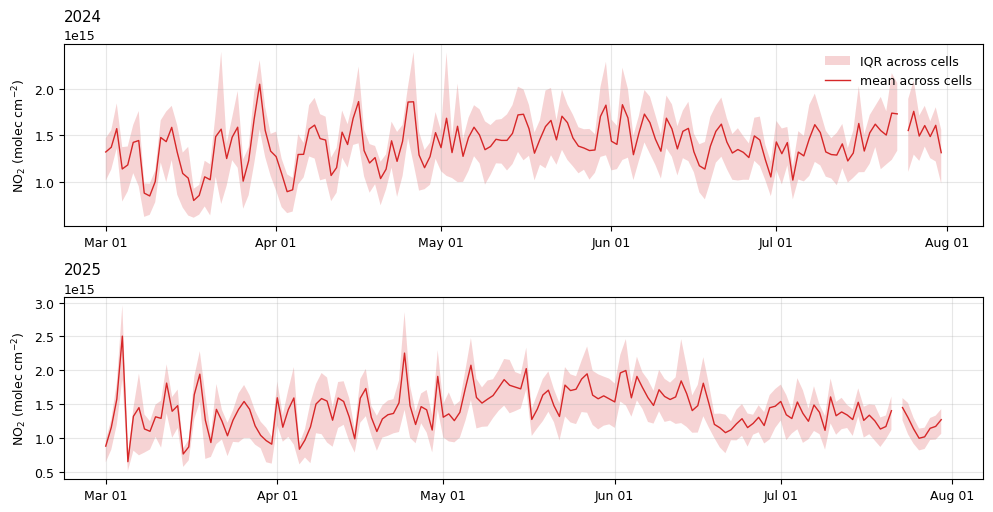

In [32]:
fig, axs = plt.subplots(len(YEARS), 1, figsize=(10, 2.6 * len(YEARS)), squeeze=False)
for ax, y in zip(axs[:, 0], YEARS):
    t = DOM[y]
    ax.fill_between(t.index, t.no2_lo, t.no2_hi, color="tab:red", alpha=0.2, lw=0, label="IQR across cells")
    ax.plot(t.index, t.no2, color="tab:red", lw=1, label="mean across cells")
    ax.set_ylabel("NO$_2$ (molec cm$^{-2}$)"); ax.set_title(str(y), loc="left"); ax.grid(alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axs[0, 0].legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig("NO2_domain_timeseries.pdf"); plt.show()

## 2–3. Exemplar event: NO$_2$ and WFPS over the whole season

In [33]:
def plot_event(y, eid=None):
    g = GRP[y]
    if eid is None:
        eid = g.drop_duplicates(["group_id", "grid_lat", "grid_lon"])["group_id"].value_counts().idxmax()
    p = g[g["group_id"] == eid].assign(datetime_local=lambda d: pd.to_datetime(d["datetime_local"]))
    cells = p[["grid_lat", "grid_lon"]].drop_duplicates()
    ev = across_cells(CD[y].merge(cells, on=["grid_lat", "grid_lon"]))
    t0, t1 = p["datetime_local"].min(), p["datetime_local"].max()

    fig, (ap, aw, an) = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3, 1.6]})
    ap.bar(ev.index, ev.precip, color="steelblue", width=0.9); ap.set_ylabel("Precip\n(mm day$^{-1}$)")
    aw.fill_between(ev.index, ev.wfps_lo, ev.wfps_hi, color="olivedrab", alpha=0.2, lw=0)
    aw.plot(ev.index, ev.wfps, color="olivedrab", lw=1.2); aw.set_ylabel("WFPS")
    an.plot(DOM[y].index, DOM[y].no2, color="grey", lw=0.8, label="domain mean")
    an.fill_between(ev.index, ev.no2_lo, ev.no2_hi, color="tab:red", alpha=0.2, lw=0)
    an.plot(ev.index, ev.no2, color="tab:red", lw=1.2, marker="o", ms=2, label=f"event {eid} cells (daily mean)")
    an.set_ylabel("NO$_2$ (molec cm$^{-2}$)"); an.legend(frameon=False, loc="upper right")
    for a in (ap, aw, an):
        a.axvspan(t0.normalize(), t1.normalize() + pd.Timedelta(days=1), color="gold", alpha=0.35, lw=0, zorder=0)
        a.grid(alpha=0.3)
    an.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ap.set_title(f"{y} | event {eid} | {len(cells)} cells |{t0:%b %d %H:%M}–{t1:%b %d %H:%M} local "
                 f"| centre ({cells.grid_lat.mean():.2f}°N, {abs(cells.grid_lon.mean()):.2f}°W)", loc="left", fontsize=9)
    fig.tight_layout(); fig.savefig(f"Event_{y}_{eid}_season_NO2_WFPS.pdf"); plt.show()

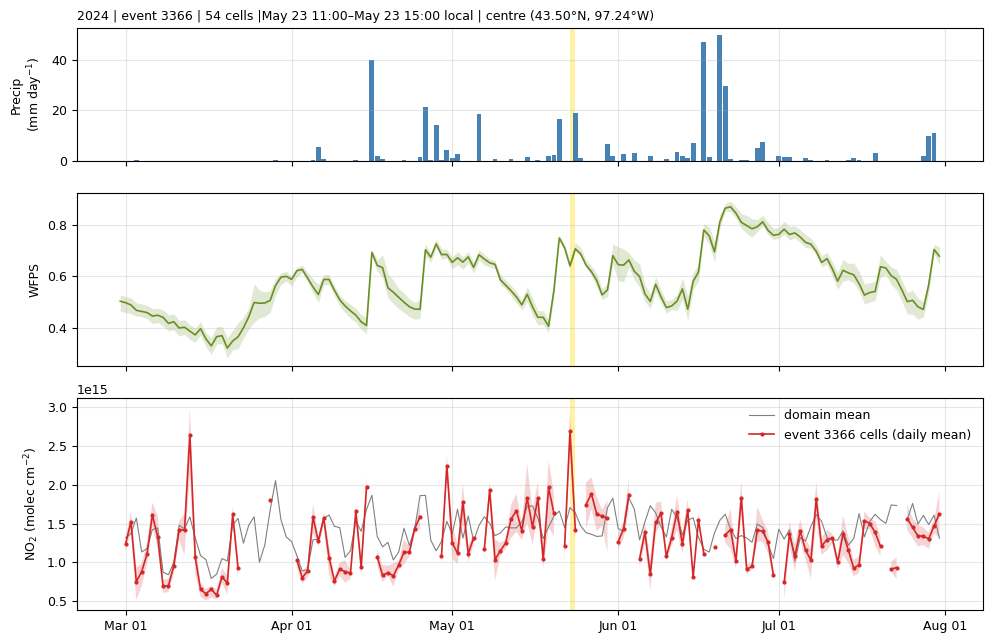

In [34]:
plot_event(2024, EVENT[2024])

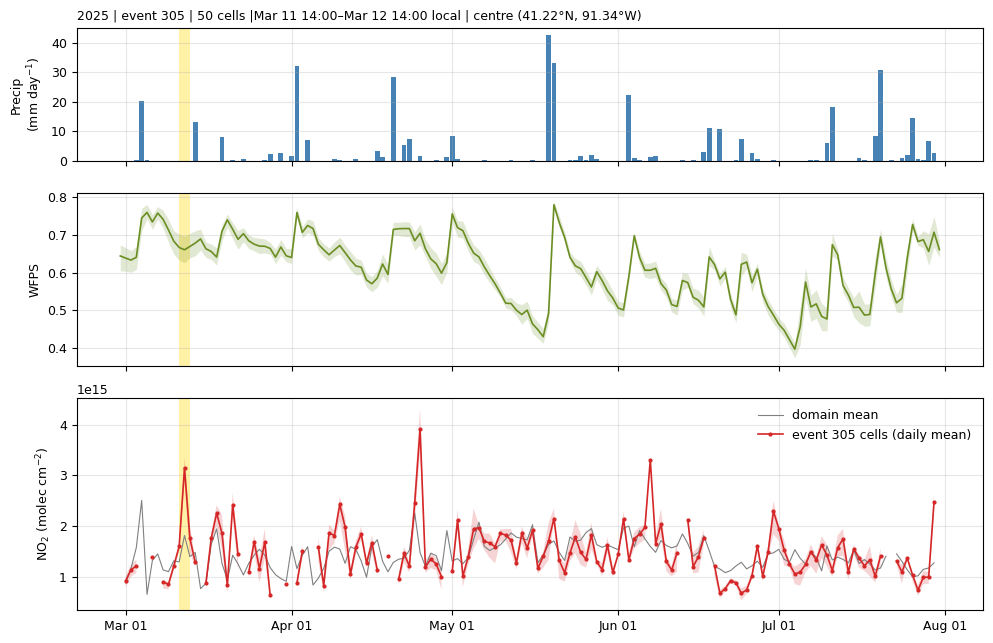

In [35]:
plot_event(2025, EVENT[2025])